# K-Means Clustering

K-Means is an unsupervised machine learning algorithm used to group similar data points into clusters based on their features.

 K-Means identifies patterns and structures within the data.

The algorithm partitions observations into K clusters, where each observation belongs to the cluster with the nearest mean (centroid).

## How K-Means Works

1. Select the number of clusters (K).
2. Initialize K cluster centroids.
3. Assign each observation to its nearest centroid.
4. Recalculate centroids based on the assigned observations.
5. Repeat the assignment and centroid update steps until convergence.

## Key Concepts

- **Centroid:** The mean position of all observations within a cluster.
- **Inertia:** The sum of squared distances between observations and their assigned cluster centroids.
- **K:** The number of clusters specified before training.

## Advantages

- Simple and computationally efficient.
- Easy to implement and interpret.
- Works well with clearly separated clusters.
- Scales reasonably well to larger datasets.

## Limitations

- Requires the number of clusters to be specified.
- Sensitive to feature scaling and outliers.
- Can converge to local optima.
- Performs poorly with irregularly shaped clusters.

## Applications

- Customer segmentation.
- Market research.
- Document grouping.
- Image segmentation.
- Pattern recognition.

In [91]:
# Imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)

import warnings
warnings.filterwarnings('ignore')

### Synthetic dataset

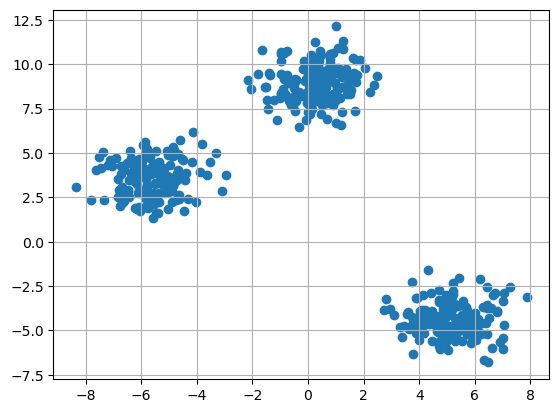

In [92]:
from sklearn.datasets import make_blobs
# custom dataset
X,y = make_blobs(n_samples = 500,n_features = 2,centers = 3,random_state = 23)

fig = plt.figure(0)
plt.grid(True)
plt.scatter(X[:,0],X[:,1])
plt.show()

In [93]:
# feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [94]:
# random centroids
k = 3

clusters = {}
np.random.seed(23)

for idx in range(k):
    center = 2*(2*np.random.random((X.shape[1],))-1)
    points = []
    cluster = {
        'center' : center,
        'points' : []
    }
    
    clusters[idx] = cluster
    
clusters

{0: {'center': array([0.06919154, 1.78785042]), 'points': []},
 1: {'center': array([ 1.06183904, -0.87041662]), 'points': []},
 2: {'center': array([-1.11581855,  0.74488834]), 'points': []}}

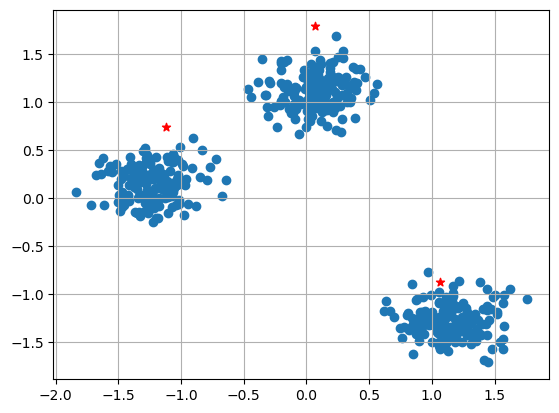

In [95]:
plt.scatter(X[:,0],X[:,1])
plt.grid(True)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = '*',c = 'red')
plt.show()

In [96]:
# Euclidean distance
def distance(p1,p2):
    return np.sqrt(np.sum((p1-p2)**2))

In [97]:
def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist = []
        
        curr_x = X[idx]
        
        for i in range(k):
            dis = distance(curr_x,clusters[i]['center'])
            dist.append(dis)
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]['points'].append(curr_x)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points = np.array(clusters[i]['points'])
        if points.shape[0] > 0:
            new_center = points.mean(axis =0)
            clusters[i]['center'] = new_center
            
            clusters[i]['points'] = []
    return clusters

In [98]:
def pred_cluster(X, clusters):
    pred = []
    for i in range(X.shape[0]):
        dist = []
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

In [99]:
# Repeat until convergence or maximum iterations
max_iters = 100

for _ in range(max_iters):
    old_centers = [clusters[i]['center'].copy() for i in range(k)]

    clusters = assign_clusters(X, clusters)
    clusters = update_clusters(X, clusters)

    new_centers = [clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred = pred_cluster(X, clusters)

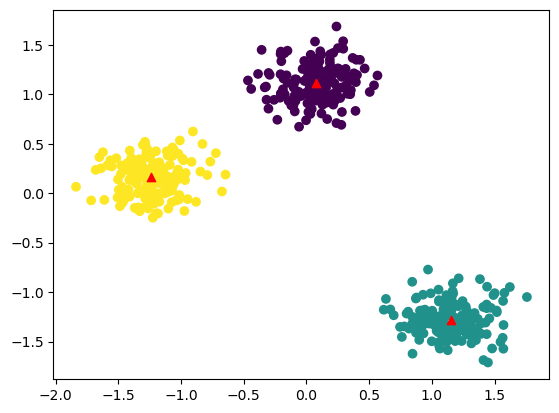

In [100]:
plt.scatter(X[:,0],X[:,1],c = pred)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = '^',c = 'red')
plt.show()

### Iris dataset

In [101]:
iris = load_iris()

iris_df = pd.DataFrame(iris.data,columns=iris.feature_names)

print(iris_df.shape)
iris_df.head()

(150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [102]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [103]:
iris_df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')

In [104]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [105]:
iris_df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

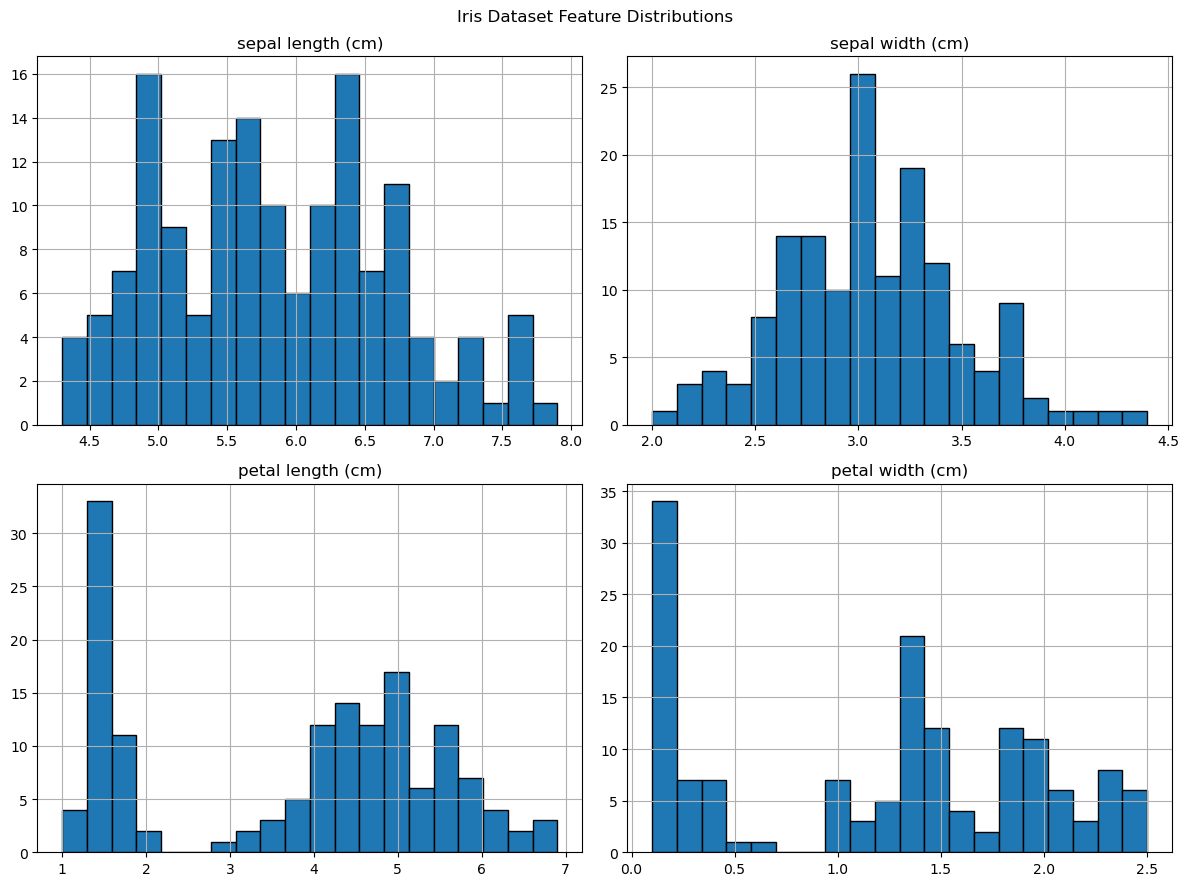

In [106]:
# features distribution
iris_df.hist(figsize=(12, 9),bins=20,edgecolor='black')

plt.suptitle("Iris Dataset Feature Distributions")
plt.tight_layout()
plt.show()

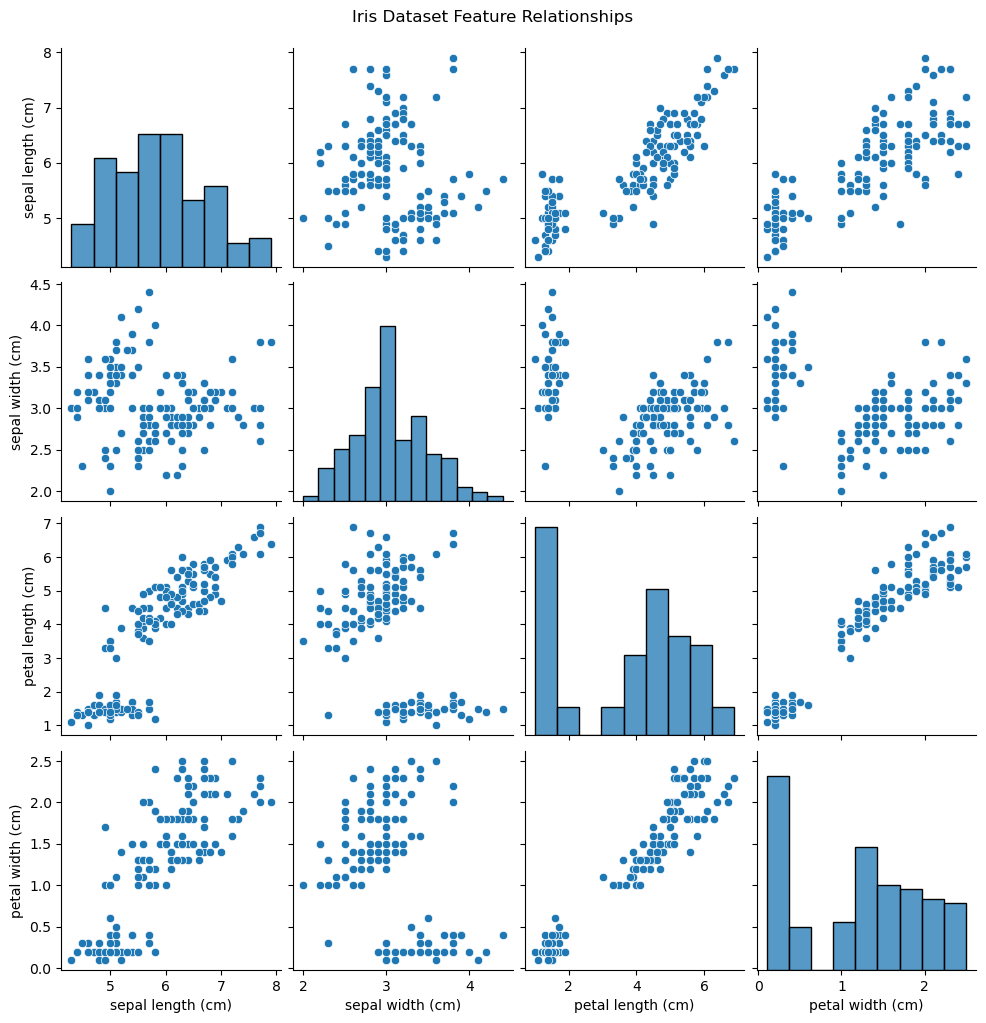

In [107]:
# feature rlships
sns.pairplot(iris_df, diag_kind='hist')

plt.suptitle("Iris Dataset Feature Relationships", y=1.02)
plt.show()

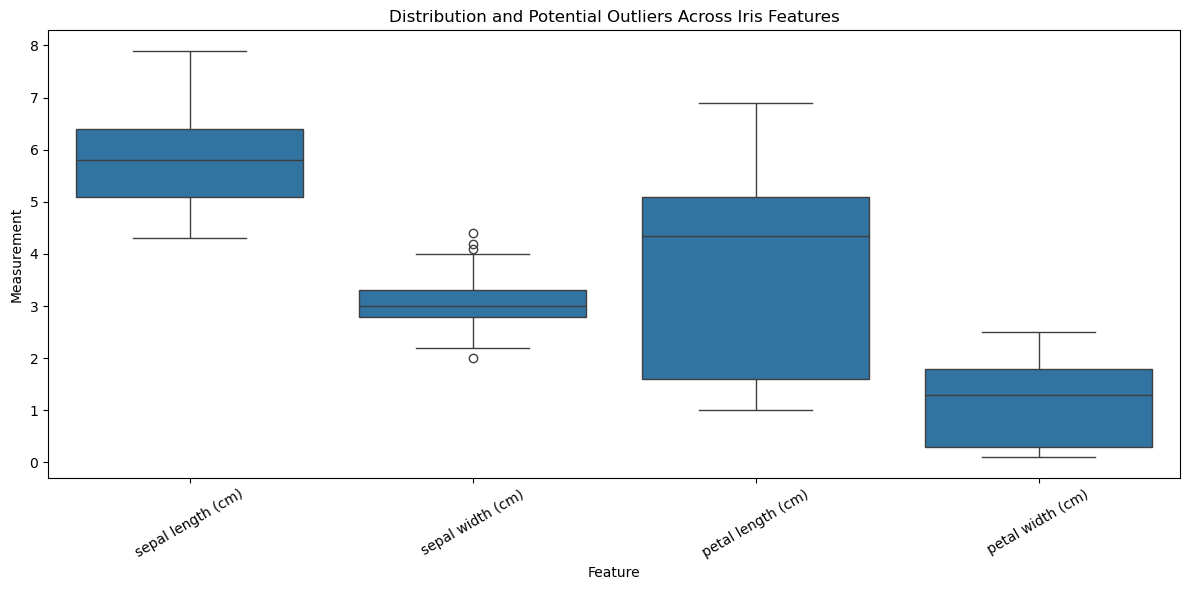

In [108]:
# outliers
plt.figure(figsize=(12, 6))

iris_melted = iris_df.melt(var_name='Feature',value_name='Measurement')

sns.boxplot(data=iris_melted,x='Feature',y='Measurement')

plt.title("Distribution and Potential Outliers Across Iris Features")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

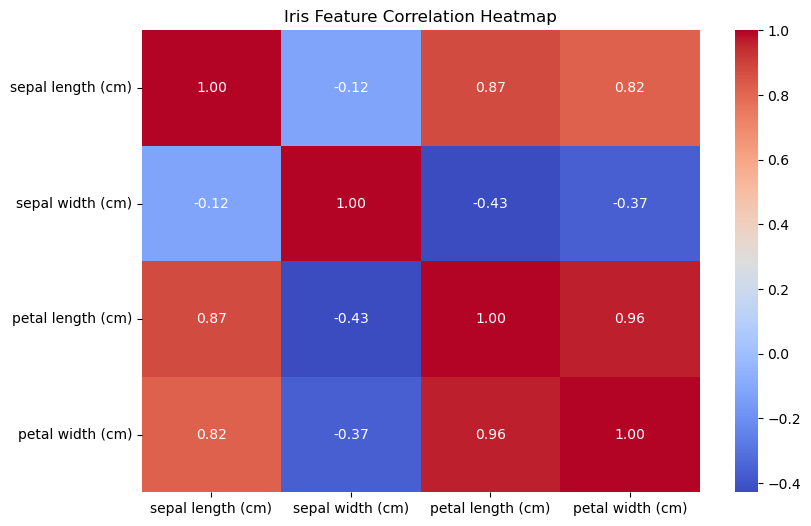

In [109]:
# correlation
plt.figure(figsize=(9, 6))

sns.heatmap(iris_df.corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title("Iris Feature Correlation Heatmap")
plt.show()

In [110]:
# Preprocessing
X = iris_df.copy()

In [111]:
# feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [112]:
X.duplicated().sum()

np.int64(1)

In [113]:
X_scaled = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

In [114]:
# inertia
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

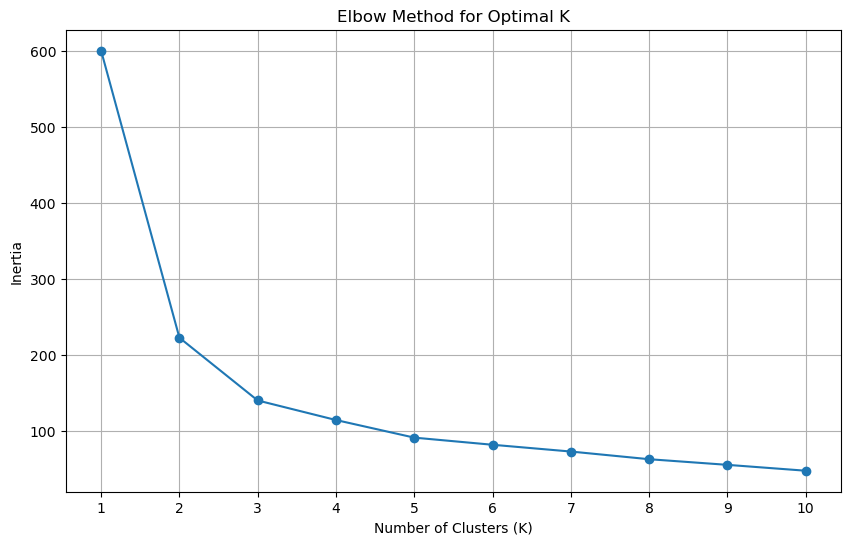

In [115]:
# Elnow curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(range(1, 11), inertia, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [116]:
for k, value in enumerate(inertia, start=1):
    print(f"K = {k}, Inertia = {value:.4f}")

K = 1, Inertia = 600.0000
K = 2, Inertia = 222.3617
K = 3, Inertia = 139.8205
K = 4, Inertia = 114.0925
K = 5, Inertia = 90.9275
K = 6, Inertia = 81.5444
K = 7, Inertia = 72.6311
K = 8, Inertia = 62.5406
K = 9, Inertia = 55.1195
K = 10, Inertia = 47.3910


In [117]:
# Modelling
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(X_scaled)

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [118]:
# cluster assignment
clusters = kmeans.labels_
clusters

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 0, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

In [119]:
# cluster labels
clustered_df = X_scaled.copy()

clustered_df['Cluster'] = clusters
clustered_df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,-0.900681,1.019004,-1.340227,-1.315444,1
1,-1.143017,-0.131979,-1.340227,-1.315444,1
2,-1.385353,0.328414,-1.397064,-1.315444,1
3,-1.506521,0.098217,-1.283389,-1.315444,1
4,-1.021849,1.249201,-1.340227,-1.315444,1
5,-0.537178,1.939791,-1.169714,-1.052180,1
6,-1.506521,0.788808,-1.340227,-1.183812,1
7,-1.021849,0.788808,-1.283389,-1.315444,1
8,-1.748856,-0.362176,-1.340227,-1.315444,1
9,-1.143017,0.098217,-1.283389,-1.447076,1


In [120]:
# cluster centroids
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X_scaled.columns
)

centroids

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526


In [121]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [122]:
pca_df = pd.DataFrame(X_pca,columns=['PC1', 'PC2'])

pca_df['Cluster'] = clusters

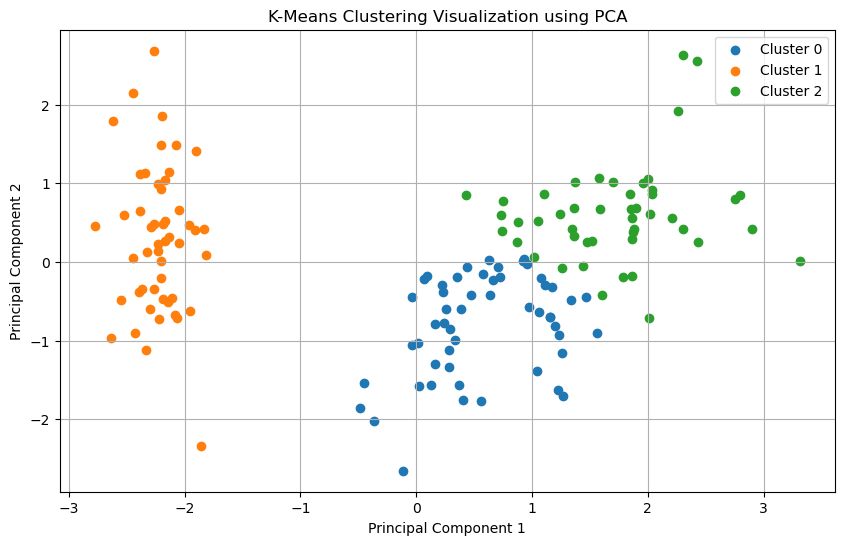

In [123]:
plt.figure(figsize=(10, 6))

for cluster in sorted(pca_df['Cluster'].unique()):
    subset = pca_df[pca_df['Cluster'] == cluster]

    plt.scatter(subset['PC1'],subset['PC2'],label=f'Cluster {cluster}')

plt.title('K-Means Clustering Visualization using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)

plt.show()

In [124]:
print("Inertia:", kmeans.inertia_)

Inertia: 139.8204963597497


In [125]:
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", sil_score)

Silhouette Score: 0.45994823920518646


In [126]:
from sklearn.metrics import davies_bouldin_score

db_score = davies_bouldin_score(X_scaled, clusters)

print("Davies-Bouldin Index:", db_score)

Davies-Bouldin Index: 0.8335949464754334


In [127]:
from sklearn.metrics import calinski_harabasz_score

ch_score = calinski_harabasz_score(X_scaled, clusters)

print("Calinski-Harabasz Score:", ch_score)

Calinski-Harabasz Score: 241.90440170183172


In [128]:
evaluation_results = pd.DataFrame({
    'Metric': [
        'Inertia',
        'Silhouette Score',
        'Davies-Bouldin Index',
        'Calinski-Harabasz Score'
    ],
    'Score': [
        kmeans.inertia_,
        sil_score,
        db_score,
        ch_score
    ]
})

evaluation_results

,Metric,Score
0,Inertia,139.820496
1,Silhouette Score,0.459948
2,Davies-Bouldin Index,0.833595
3,Calinski-Harabasz Score,241.904402


In [129]:
# Train models with different K values
results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        'K': k,
        'Inertia': model.inertia_,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels),
        'Calinski-Harabasz Score': calinski_harabasz_score(X_scaled, labels)
    })

In [130]:
comparison_df = pd.DataFrame(results)

comparison_df

,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,222.361705,0.581750,0.593313,251.349339
1,3,139.820496,0.459948,0.833595,241.904402
2,4,114.092547,0.386941,0.869814,207.265914
3,5,90.927514,0.345901,0.948317,202.951525
4,6,81.544391,0.317079,1.053677,183.109118
5,7,72.631144,0.320197,0.990528,173.051904
6,8,62.540606,0.338692,0.914982,174.330702
7,9,55.119493,0.342360,0.903152,174.230902
8,10,47.391035,0.351793,0.874825,181.387459


In [131]:
print("Best Silhouette Score:")
print(comparison_df.loc[comparison_df['Silhouette Score'].idxmax()])

print("\nBest Davies-Bouldin Index:")
print(comparison_df.loc[comparison_df['Davies-Bouldin Index'].idxmin()])

print("\nBest Calinski-Harabasz Score:")
print(comparison_df.loc[comparison_df['Calinski-Harabasz Score'].idxmax()])

Best Silhouette Score:
K                            2.000000
Inertia                    222.361705
Silhouette Score             0.581750
Davies-Bouldin Index         0.593313
Calinski-Harabasz Score    251.349339
Name: 0, dtype: float64

Best Davies-Bouldin Index:
K                            2.000000
Inertia                    222.361705
Silhouette Score             0.581750
Davies-Bouldin Index         0.593313
Calinski-Harabasz Score    251.349339
Name: 0, dtype: float64

Best Calinski-Harabasz Score:
K                            2.000000
Inertia                    222.361705
Silhouette Score             0.581750
Davies-Bouldin Index         0.593313
Calinski-Harabasz Score    251.349339
Name: 0, dtype: float64


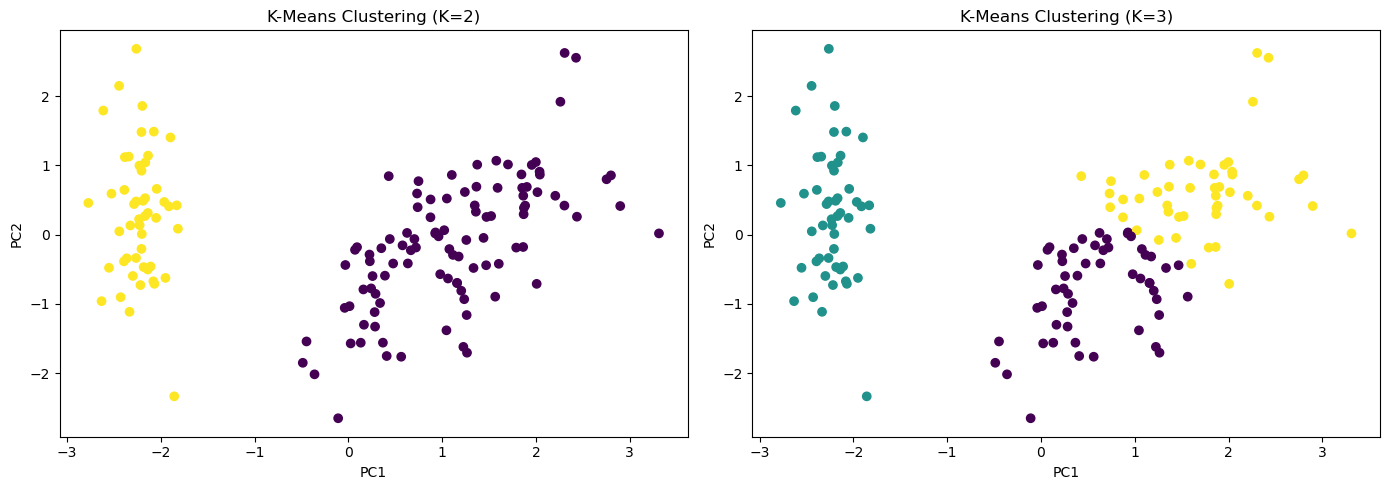

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, k in zip(axes, [2, 3]):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    ax.scatter(X_pca[:, 0],X_pca[:, 1],c=labels)

    ax.set_title(f'K-Means Clustering (K={k})')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')

plt.tight_layout()
plt.show()

## Conclusion

In this project, K-Means clustering was implemented to identify patterns and group observations in the Iris dataset using its four numerical features.

The dataset was preprocessed and standardized using `StandardScaler` to ensure that all features contributed appropriately to distance calculations.

The Elbow Method was used to estimate the optimal number of clusters, suggesting K = 3. The model was subsequently trained with three clusters, and its results were visualized using Principal Component Analysis (PCA).

Model performance was evaluated using Inertia, Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score. Further experimentation compared different cluster numbers, with K = 2 achieving the strongest results across the three internal cluster separation metrics.

The comparison demonstrated that the number of clusters producing the best internal evaluation scores does not necessarily correspond to the number of naturally occurring categories in a dataset.

### Key Takeaways

- K-Means discovers patterns in unlabelled data without requiring a target variable.
- Feature scaling is important because K-Means relies on distance calculations.
- The Elbow Method helps estimate a suitable number of clusters.
- PCA makes high-dimensional clustering results easier to visualize.
- Internal evaluation metrics provide different perspectives on clustering quality.
- Selecting the number of clusters requires considering both evaluation metrics and the purpose of the analysis.

Overall, this project provided practical experience in unsupervised learning, clustering, dimensionality reduction, model evaluation, and interpreting discovered patterns.

## K-Means++ Clustering

K-Means++ is an improved initialization technique for the K-Means clustering algorithm. It addresses one of the limitations of traditional K-Means, which is the random selection of initial cluster centroids.

Poor initial centroid selection can lead to inconsistent clustering results and convergence to suboptimal solutions.

K-Means++ improves the initialization process by selecting the first centroid randomly and choosing subsequent centroids based on their squared distances from the nearest existing centroid. This encourages the initial centroids to be spread across the dataset.

After initialization, the standard K-Means algorithm continues by assigning observations to their nearest centroids and updating the centroids iteratively.

### Objectives

- Understand the K-Means++ initialization technique.
- Explore how K-Means++ selects initial centroids.
- Implement K-Means++ using Scikit-learn.
- Compare its performance with traditional K-Means.

### Advantages

- Improves initial centroid selection.
- Reduces the likelihood of poor initialization.
- Can improve clustering consistency.
- Often converges to better clustering solutions.

### Limitations

- Does not guarantee the globally optimal clustering solution.
- Can require additional computation during initialization.
- Still requires the number of clusters to be specified.

In [133]:
# initialize K++ means
kmeans_pp = KMeans(n_clusters=3,init='k-means++',random_state=42,n_init=10)
kmeans_pp.fit(X_scaled)

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [134]:
clusters_pp = kmeans_pp.labels_

print(clusters_pp)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [135]:
clustered_pp_df = X_scaled.copy()

clustered_pp_df['Cluster'] = clusters_pp

clustered_pp_df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,-0.900681,1.019004,-1.340227,-1.315444,1
1,-1.143017,-0.131979,-1.340227,-1.315444,1
2,-1.385353,0.328414,-1.397064,-1.315444,1
3,-1.506521,0.098217,-1.283389,-1.315444,1
4,-1.021849,1.249201,-1.340227,-1.315444,1
5,-0.537178,1.939791,-1.169714,-1.052180,1
6,-1.506521,0.788808,-1.340227,-1.183812,1
7,-1.021849,0.788808,-1.283389,-1.315444,1
8,-1.748856,-0.362176,-1.340227,-1.315444,1
9,-1.143017,0.098217,-1.283389,-1.447076,1


In [136]:
clustered_pp_df['Cluster'].value_counts().sort_index()

Cluster
0    53
1    50
2    47
Name: count, dtype: int64

In [137]:
centroids_pp = pd.DataFrame(
    kmeans_pp.cluster_centers_,
    columns=X_scaled.columns
)

centroids_pp

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526


In [138]:
pca_pp_df = pd.DataFrame(X_pca,columns=['PC1', 'PC2'])

pca_pp_df['Cluster'] = clusters_pp

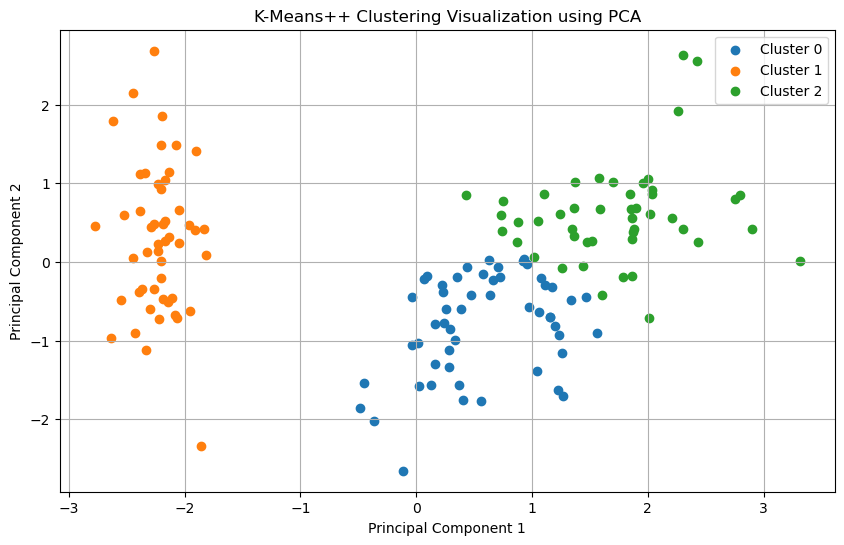

In [139]:
plt.figure(figsize=(10, 6))

for cluster in sorted(pca_pp_df['Cluster'].unique()):

    subset = pca_pp_df[pca_pp_df['Cluster'] == cluster]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=f'Cluster {cluster}'
    )

plt.title('K-Means++ Clustering Visualization using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)

plt.show()

In [140]:
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)

sil_pp = silhouette_score(X_scaled, clusters_pp)

db_pp = davies_bouldin_score(X_scaled, clusters_pp)

ch_pp = calinski_harabasz_score(X_scaled, clusters_pp)

In [141]:
evaluation_pp = pd.DataFrame({
    'Metric': [
        'Inertia',
        'Silhouette Score',
        'Davies-Bouldin Index',
        'Calinski-Harabasz Score'
    ],
    'Score': [
        kmeans_pp.inertia_,
        sil_pp,
        db_pp,
        ch_pp
    ]
})

evaluation_pp

,Metric,Score
0,Inertia,139.820496
1,Silhouette Score,0.459948
2,Davies-Bouldin Index,0.833595
3,Calinski-Harabasz Score,241.904402


In [142]:
comparison = pd.DataFrame({
    'Metric': [
        'Inertia',
        'Silhouette Score',
        'Davies-Bouldin Index',
        'Calinski-Harabasz Score'
    ],
    'K-Means': [
        kmeans.inertia_,
        silhouette_score(X_scaled, kmeans.labels_),
        davies_bouldin_score(X_scaled, kmeans.labels_),
        calinski_harabasz_score(X_scaled, kmeans.labels_)
    ],
    'K-Means++': [
        kmeans_pp.inertia_,
        sil_pp,
        db_pp,
        ch_pp
    ]
})

comparison

,Metric,K-Means,K-Means++
0,Inertia,139.820496,139.820496
1,Silhouette Score,0.459948,0.459948
2,Davies-Bouldin Index,0.833595,0.833595
3,Calinski-Harabasz Score,241.904402,241.904402


In [ ]:
## Comparison Results

The K-Means and K-Means++ models produced identical evaluation scores across all four metrics: Inertia, Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score.

This indicates that both implementations generated the same clustering results in this experiment.

The identical results are expected because Scikit-learn uses K-Means++ as its default initialization method, and both models were configured with the same parameters and random state.

Although K-Means++ improves centroid initialization compared to random initialization, no performance difference was observed between these two implementations.